# 00-4　觀看前須知：讀懂 04 廣義相對論需要的觀念

**給誰看**：讀過 [00-3](03_before_relativity.ipynb) 和 [03 狹義相對論](../03_special_relativity/01_special_relativity.ipynb) 的人。
**目標**：讀完再去看 04-1（史瓦西時空）和 04-2（重力波）。

廣義相對論的完整數學（張量微積分）是大學物理研究所的內容。但它的**核心觀念**用高中數學就能掌握，計算交給 sympy 和數值積分就好。

| 章節 | 內容 | 04 對應的地方 |
|---|---|---|
| 0 | 符號對照表 | 全部 |
| 1 | 等效原理：重力和加速度分不出來 | 04-1 的出發點 |
| 2 | 彎曲空間：球面上的「直線」 | 測地線 |
| 3 | 度規：一張「距離公式」表 | $g_{\mu\nu}$、sympy 驗證 |
| 4 | 時空間隔：把 03 的固有時寫成距離公式 | $ds^2$ |
| 5 | 逃逸速度與史瓦西半徑 | 黑洞、$r_s$ |
| 6 | 重力讓時鐘變慢 | GPS 的另一半 |
| 7 | 愛因斯坦方程式在說什麼 | 04-1 實驗 1 |
| 8 | 訊號、雜訊、濾波 | 04-2 的 LIGO 數據 |

## 0. 符號對照表

| 符號 | 念法 | 意思 |
|---|---|---|
| $ds^2$ | | 兩個很近的點之間「距離的平方」（時空版本） |
| $g_{\mu\nu}$ | g mu nu | **度規**：一張 4×4 的係數表，決定距離怎麼算，也就是時空的形狀 |
| $\mu, \nu$ | mu, nu | 下標，代表 0、1、2、3（時間和三個空間方向） |
| $G_{\mu\nu}$ | | 愛因斯坦張量：描述時空**彎曲**的一張表 |
| $T_{\mu\nu}$ | | 能量動量張量：描述**物質和能量**分佈的一張表 |
| $R_{\mu\nu}$ | | 里奇張量：另一張描述彎曲的表，真空中它等於 0 |
| $r_s$ | | 史瓦西半徑 $2GM/c^2$，黑洞「視界」的大小 |
| $\Phi$ | phi | 重力位能（每單位質量），$-GM/r$ |
| $\theta, \varphi$ | theta, phi | 球面上的角度（緯度方向、經度方向） |
| $h$ | | 04-2 裡指**應變**：重力波讓長度變化的比例 $\Delta L / L$（和普朗克常數無關） |
| Hz | 赫茲 | 每秒振動幾次 |

In [1]:
import numpy as np
import matplotlib.pyplot as plt

plt.rcParams["font.family"] = ["Microsoft JhengHei", "sans-serif"]  # 中文標籤
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 100

c = 299_792_458.0
G = 6.674e-11
M_sun, M_earth = 1.989e30, 5.972e24

## 1. 等效原理：重力和加速度分不出來

**思想實驗**：你在一台沒有窗戶的電梯裡。

- **電梯停在地面**：你感覺被往下拉，放開的球會往下掉。
- **電梯在外太空，以 9.8 m/s² 往上加速**：地板一直往上推你，放開的球「看起來」也往下掉。

**你在電梯裡做任何實驗，都分不出是哪一種。** 這就是愛因斯坦的**等效原理**（1907 年，他稱之為「一生中最快樂的想法」）。

反過來也成立：**自由落下的電梯裡，重力完全消失**，你會飄起來。國際太空站上的太空人飄浮，不是因為那裡沒有重力，而是他們**一直在自由落下**（只是同時往前飛得夠快，一直掉不到地面）：

In [2]:
R_earth = 6.371e6
for name, h in [("地面", 0), ("國際太空站（420 km）", 420e3), ("GPS 衛星（20,200 km）", 20_200e3)]:
    g_here = G * M_earth / (R_earth + h) ** 2
    print(f"{name:<22} 重力加速度 = {g_here:.2f} m/s²（地面的 {g_here / 9.82:.0%}）")

地面                     重力加速度 = 9.82 m/s²（地面的 100%）
國際太空站（420 km）          重力加速度 = 8.64 m/s²（地面的 88%）
GPS 衛星（20,200 km）      重力加速度 = 0.56 m/s²（地面的 6%）


太空站上的重力還有地面的 88%，太空人飄浮完全是因為自由落下。

**愛因斯坦從等效原理推出兩個驚人的結論**：

1. **光會被重力彎曲**：加速中的電梯裡，一道橫向射入的光，看起來會往下彎（因為地板往上衝）。既然加速度和重力分不出來，重力也必須讓光彎曲。
2. **重力讓時鐘變慢**：加速電梯的天花板往地板發訊號，訊號到達時地板已經在加速，接收到的頻率變高。換成重力：**低處的時鐘走得比高處慢**。

**最大的轉念**：既然自由落下時重力「消失」，那重力也許根本不是一種**力**。
自由落下的物體只是在**彎曲的時空裡走最直的路**。這個「最直的路」叫**測地線**。

## 2. 彎曲空間：球面上的「直線」

在彎曲的面上，什麼叫「直線」？答案是**兩點之間最短的路徑**，叫**測地線**。

地球表面就是彎曲的。在球面上，測地線是**大圓**：以球心為圓心的圓，例如赤道和所有經線。
這就是為什麼從台北飛紐約的飛機，航線會**往北繞過阿拉斯加**：在地圖上看是彎的，其實那才是「直線」。

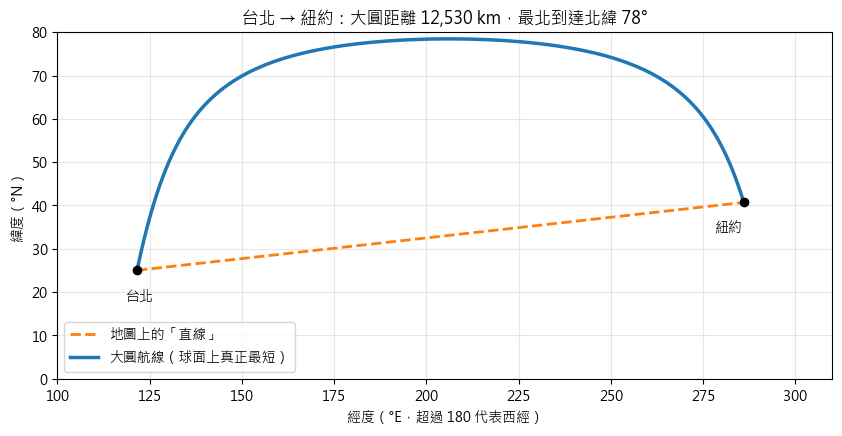

In [3]:
def to_xyz(lat, lon):
    lat, lon = np.radians(lat), np.radians(lon)
    return np.array([np.cos(lat) * np.cos(lon), np.cos(lat) * np.sin(lon), np.sin(lat)])

def great_circle(p1, p2, n=200):
    # 球面上兩點之間的最短路徑（大圓的一段）
    a, b = to_xyz(*p1), to_xyz(*p2)
    omega = np.arccos(np.clip(a @ b, -1, 1))
    t = np.linspace(0, 1, n)[:, None]
    pts = (np.sin((1 - t) * omega) * a + np.sin(t * omega) * b) / np.sin(omega)
    return np.degrees(np.arcsin(pts[:, 2])), np.degrees(np.arctan2(pts[:, 1], pts[:, 0])), omega

taipei, new_york = (25.03, 121.57), (40.71, -74.01 + 360)   # 經度加 360，讓地圖不跨換日線
lat_g, lon_g, omega = great_circle(taipei, new_york)
lon_g = np.where(lon_g < 0, lon_g + 360, lon_g)
R_km = 6371

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot([taipei[1], new_york[1]], [taipei[0], new_york[0]], "C1--", lw=2, label="地圖上的「直線」")
ax.plot(lon_g, lat_g, "C0", lw=2.5, label="大圓航線（球面上真正最短）")
ax.plot(*taipei[::-1], "ko")
ax.text(taipei[1] - 3, taipei[0] - 7, "台北")
ax.plot(*new_york[::-1], "ko")
ax.text(new_york[1] - 8, new_york[0] - 7, "紐約")
ax.set_xlim(100, 310)
ax.set_ylim(0, 80)
ax.set_xlabel("經度（°E，超過 180 代表西經）")
ax.set_ylabel("緯度（°N）")
ax.set_title(f"台北 → 紐約：大圓距離 {omega * R_km:,.0f} km，最北到達北緯 {lat_g.max():.0f}°")
ax.legend(loc="lower left")
ax.grid(alpha=0.3)
plt.show()

**彎曲空間的怪事：三角形內角和不是 180°。**

從北極出發，沿經線往南走到赤道，沿赤道往東走四分之一圈，再沿經線走回北極。
這個三角形的三個角都是 90°，**內角和 270°**。

在平面上，三角形內角和永遠是 180°。**內角和多出來的量，就代表空間有多彎**。而且住在球面上的螞蟻，**不用離開球面**，只要量三角形就能發現自己住在彎曲的空間裡。
這正是廣義相對論的想法：我們不用「離開」時空，就能量出時空是彎的。

## 3. 度規：一張「距離公式」表

**平面上**，兩個很近的點之間的距離（畢氏定理）：

$$ds^2 = dx^2 + dy^2$$

**同一個平面，改用極座標**（距離 $r$、角度 $\varphi$）：

$$ds^2 = dr^2 + r^2\,d\varphi^2$$

$d\varphi$ 前面多了 $r^2$，因為離中心越遠，轉同樣的角度走得越多。空間還是平的，只是座標不同。

**球面上**（半徑 $R$，$\theta$ 是從北極量起的角度，$\varphi$ 是經度）：

$$ds^2 = R^2\,d\theta^2 + R^2\sin^2\theta\,d\varphi^2$$

**度規**就是 $ds^2$ 公式裡各項前面的**係數**，排成一張表。例如球面的度規是

$$g = \begin{pmatrix} R^2 & 0 \\ 0 & R^2\sin^2\theta \end{pmatrix}$$

**只要知道度規，就能算出所有的距離、角度、測地線和彎曲程度。** 度規就是空間的「形狀」。
04-1 會給 sympy 一張時空的度規，讓它算出時空彎曲，證明那是愛因斯坦方程式的解。

**親手看**：在球面上，用度規量「圓周長 ÷ 半徑」：

In [4]:
R = 1.0
print(f"{'從北極走的距離 r':>16}{'圓周長 C':>12}{'C / (2πr)':>12}")
for theta in [0.01, 0.3, 0.6, 1.0, np.pi / 2]:
    r = R * theta                        # 沿球面從北極量起的「半徑」
    circumference = 2 * np.pi * R * np.sin(theta)   # 用度規：沿 φ 繞一圈，ds = R sinθ dφ
    print(f"{r:>16.3f}{circumference:>12.4f}{circumference / (2 * np.pi * r):>12.4f}")

       從北極走的距離 r       圓周長 C   C / (2πr)
           0.010      0.0628      1.0000
           0.300      1.8568      0.9851
           0.600      3.5478      0.9411
           1.000      5.2871      0.8415
           1.571      6.2832      0.6366


在平面上，$C / 2\pi r$ 永遠是 1。在球面上，圓越大，這個比值就越小於 1（赤道只有 0.64）。
**住在球面上的人量圓周長，就能知道空間是彎的。**

## 4. 時空間隔：把 03 的固有時寫成距離公式

03 的雙生子實驗用了 $\tau = \int\sqrt{1 - v^2/c^2}\,dt$。把它寫成距離公式的樣子：

$$ds^2 = -c^2\,dt^2 + dx^2 + dy^2 + dz^2,\qquad d\tau^2 = -\frac{ds^2}{c^2}$$

這叫**閔考斯基度規**，狹義相對論的平坦時空。和平面的畢氏定理只差一個地方：**時間那一項是負的**。

這個負號就是 03 所有怪事的來源：

- 它讓**直線是固有時最長的路徑**（雙生子悖論），而不是最短
- 它讓光走的路徑 $ds^2 = 0$，所以光的「固有時」永遠是 0

**廣義相對論**就是把這些係數換成**會隨位置改變**的數：
$$ds^2 = g_{\mu\nu}\,dx^\mu dx^\nu$$
物質讓這些係數改變，時空就彎了。04-1 的史瓦西度規就是一個例子。

In [5]:
# 用時空間隔重算 03 的雙生子：沿著世界線把 dτ = √(dt² − dx²/c²) 加起來（單位：年、光年，c = 1）
t = np.linspace(0, 10, 10001)
x = np.where(t < 5, 0.8 * t, 8 - 0.8 * t)
dtau = np.sqrt(np.diff(t) ** 2 - np.diff(x) ** 2)
print(f"姊姊：τ = {t[-1]:.2f} 年；妹妹：τ = {dtau.sum():.2f} 年（和 03 實驗 4 一樣）")

姊姊：τ = 10.00 年；妹妹：τ = 6.00 年（和 03 實驗 4 一樣）


## 5. 逃逸速度與史瓦西半徑

**高中物理**：從星球表面要多快才能飛走、不再掉回來？讓動能剛好等於逃離需要的能量：

$$\frac12 mv^2 = \frac{GMm}{r}\quad\Rightarrow\quad v_{\text{逃逸}} = \sqrt{\frac{2GM}{r}}$$

**如果逃逸速度等於光速**，連光都逃不出來。解出那個半徑：

$$r_s = \frac{2GM}{c^2}$$

這就是**史瓦西半徑**。1783 年英國的 John Michell 就用牛頓力學想到了「暗星」。
巧的是，廣義相對論算出的黑洞視界大小**剛好也是這個公式**（雖然推導的理由完全不同）。

In [6]:
objects = [("地球", M_earth, 6.371e6), ("太陽", M_sun, 6.96e8), ("一個人（70 kg）", 70, 0.3),
           ("GW150914 合併後的黑洞（62 倍太陽）", 62 * M_sun, None)]
print(f"{'物體':<30}{'史瓦西半徑':>16}{'實際半徑':>14}{'表面逃逸速度':>14}")
for name, M, R in objects:
    rs = 2 * G * M / c**2
    if rs > 1:
        rs_str = f"{rs / 1000:.1f} km"
    elif rs > 1e-6:
        rs_str = f"{rs * 1000:.1f} mm"
    else:
        rs_str = f"{rs:.1e} m"
    if R is None:
        R_str, v_str = "（它就是黑洞）", "c"
    else:
        R_str = f"{R / 1000:,.0f} km" if R > 1000 else f"{R} m"
        v = np.sqrt(2 * G * M / R)
        v_str = f"{v / 1000:.1f} km/s" if v > 1 else f"{v:.1e} m/s"
    print(f"{name:<28}{rs_str:>16}{R_str:>14}{v_str:>14}")

物體                                       史瓦西半徑          實際半徑        表面逃逸速度
地球                                    8.9 mm      6,371 km     11.2 km/s
太陽                                    3.0 km    696,000 km    617.6 km/s
一個人（70 kg）                         1.0e-25 m         0.3 m   1.8e-04 m/s
GW150914 合併後的黑洞（62 倍太陽）             183.1 km       （它就是黑洞）             c


把整個地球壓縮到一顆彈珠（9 mm）那麼小，它就會變成黑洞。太陽要壓到 3 公里。
一般星球的實際半徑都遠大於 $r_s$，所以廣義相對論的效應很小，**但不是零**：04-1 要算的水星進動和 GPS 都來自這個「很小但不是零」。

## 6. 重力讓時鐘變慢

第 1 章說低處的時鐘比較慢。在重力不強的時候，慢的比例是

$$\frac{\Delta t_{\text{低處}}}{\Delta t_{\text{遠處}}} \approx 1 + \frac{\Phi}{c^2} = 1 - \frac{GM}{rc^2}$$

$\Phi = -GM/r$ 是重力位能（每單位質量）。越靠近地球，$\Phi$ 越負，時鐘越慢。

**兩個高度的時鐘差多少**：比例差約 $g\,\Delta h / c^2$（$g$ 是重力加速度，$\Delta h$ 是高度差）。

In [7]:
g_surface = 9.81
for name, dh in [("1959 年 Pound–Rebka 實驗（哈佛的塔，22.5 m）", 22.5),
                 ("2010 年光學原子鐘（墊高 33 cm）", 0.33),
                 ("台北 101 頂樓（508 m）", 508),
                 ("玉山頂（3952 m）", 3952)]:
    frac = g_surface * dh / c**2
    print(f"{name:<38} 比例差 {frac:.2e}，一天差 {frac * 86400 * 1e9:8.3g} ns")

1959 年 Pound–Rebka 實驗（哈佛的塔，22.5 m）     比例差 2.46e-15，一天差    0.212 ns
2010 年光學原子鐘（墊高 33 cm）                  比例差 3.60e-17，一天差  0.00311 ns
台北 101 頂樓（508 m）                       比例差 5.54e-14，一天差     4.79 ns
玉山頂（3952 m）                            比例差 4.31e-13，一天差     37.3 ns


- 1959 年 Pound 和 Rebka 在 22.5 公尺高的塔上，用伽瑪射線的頻率變化量到了 $2.5\times10^{-15}$ 的差異，第一次在實驗室證實重力讓時間變慢。
- 2010 年美國 NIST 的光學原子鐘，把一台鐘墊高 **33 公分**，就量到了差異。
- 住在玉山頂的人，一輩子（80 年）會比住在海邊的人多老大約 **1 毫秒**。

GPS 衛星在兩萬公里高，這個效應很大，而且方向和 03 的「速度讓時鐘變慢」**相反**。04-1 會把兩個效應加起來。

## 7. 愛因斯坦方程式在說什麼

$$G_{\mu\nu} = \frac{8\pi G}{c^4}\,T_{\mu\nu}$$

- **左邊** $G_{\mu\nu}$：時空**彎曲**的程度，從度規 $g_{\mu\nu}$ 算出來（要對度規做好幾次微分）
- **右邊** $T_{\mu\nu}$：那裡有多少**物質和能量**

物理學家 Wheeler 的一句話總結：

> **物質告訴時空怎麼彎曲，時空告訴物質怎麼運動。**

**真空中**（例如太陽外面），右邊是 0，方程式變成 $R_{\mu\nu} = 0$。
1915 年底，史瓦西在一次大戰的前線上，找到了這個方程式在「一顆球形星球外面」的精確解，就是 04-1 要驗證的**史瓦西度規**。

左邊的計算（從度規算出 $R_{\mu\nu}$）非常繁瑣，人工算要好幾頁，這正是 sympy 擅長的工作。

**和量子力學的衝突就藏在這條方程式裡**：右邊的物質是量子的（有疊加、有不確定性），左邊的時空卻是古典的、確定的。這是我們最早討論的第 3 點，05 單元會用模擬呈現。

## 8. 訊號、雜訊、濾波（為 04-2 準備）

04-2 會分析 LIGO 偵測到的第一個重力波。先熟悉三個觀念：

**1. 啁啾訊號**（chirp）：兩個黑洞互相繞轉時，越轉越近、越轉越快，發出的重力波**頻率和振幅一起升高**，像鳥叫的「啾～」。

**2. 雜訊**：重力波極其微弱。LIGO 量的是 4 公里長的手臂被拉伸的比例 $h = \Delta L / L$，GW150914 的 $h$ 只有約 $10^{-21}$：

In [8]:
L_arm = 4000.0
h_strain = 1e-21
dL = h_strain * L_arm
print(f"手臂長度變化 ΔL = {dL:.0e} m")
print(f"質子直徑約 1.7e-15 m → ΔL 是質子的 {dL / 1.7e-15:.4f} 倍（約千分之 {dL / 1.7e-15 * 1000:.1f}）")

手臂長度變化 ΔL = 4e-18 m
質子直徑約 1.7e-15 m → ΔL 是質子的 0.0024 倍（約千分之 2.4）


真實數據裡，訊號完全**淹沒在雜訊**裡（地震、海浪、熱振動、雷射本身的量子雜訊）。

**3. 濾波**：雜訊大多集中在某些頻率（很低頻的地面振動、特定頻率的電力干擾）。
只保留訊號所在的頻率範圍（**帶通濾波**），並把每個頻率的雜訊**拉成一樣大**（**白化**），訊號就會浮出來。

**親手看**：做一個假的啁啾訊號，埋進比它大 10 倍的雜訊裡，再濾出來：

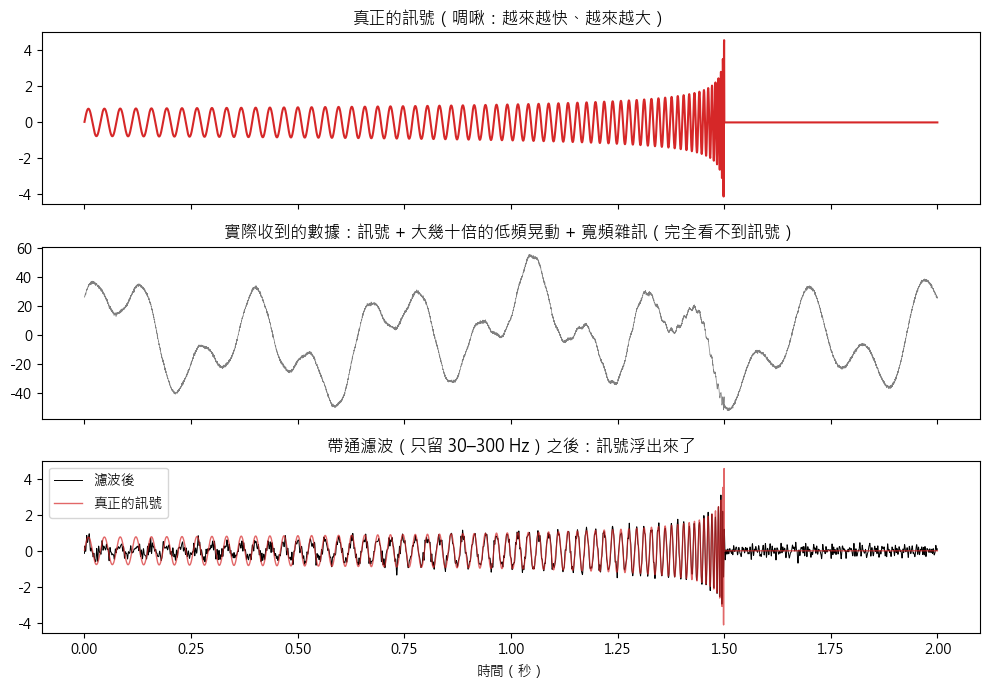

In [9]:
from scipy.signal import butter, sosfiltfilt

fs = 4096                                   # 每秒取樣 4096 次（和 LIGO 公開數據一樣）
t = np.arange(0, 2, 1 / fs)
t_merge = 1.5
tau = np.clip(t_merge - t, 1e-3, None)
freq = 40 * (tau / 0.5) ** (-3 / 8)         # 頻率隨時間升高（啁啾）
phase = 2 * np.pi * np.cumsum(freq) / fs
chirp = np.where(t < t_merge, (freq / 40) ** (2 / 3) * np.sin(phase), 0)

rng = np.random.default_rng(0)
# 雜訊 = 很強的低頻晃動（像地面振動，比訊號大幾十倍）+ 比訊號小的寬頻雜訊
ground = 25 * np.sin(2 * np.pi * 3.1 * t) + 18 * np.sin(2 * np.pi * 7.7 * t + 1.0) + 12 * np.sin(2 * np.pi * 0.9 * t + 2.0)
noise = ground + rng.normal(0, 0.5, t.size)
data = chirp + noise

sos = butter(4, [30, 300], btype="bandpass", fs=fs, output="sos")
filtered = sosfiltfilt(sos, data)

fig, axes = plt.subplots(3, 1, figsize=(10, 7), sharex=True)
axes[0].plot(t, chirp, "C3")
axes[0].set_title("真正的訊號（啁啾：越來越快、越來越大）")
axes[1].plot(t, data, "gray", lw=0.5)
axes[1].set_title("實際收到的數據：訊號 + 大幾十倍的低頻晃動 + 寬頻雜訊（完全看不到訊號）")
axes[2].plot(t, filtered, "k", lw=0.7, label="濾波後")
axes[2].plot(t, chirp, "C3", lw=1, alpha=0.7, label="真正的訊號")
axes[2].set_title("帶通濾波（只留 30–300 Hz）之後：訊號浮出來了")
axes[2].legend(loc="upper left")
axes[2].set_xlabel("時間（秒）")
plt.tight_layout()
plt.show()

04-2 會對真正的 LIGO 數據做同樣的事，再加上**白化**和**頻譜圖**（同時看時間和頻率），讓 2015 年 9 月 14 日那一聲「啾」出現在你的螢幕上。

## 準備好了：去讀 04

| 你在 04 看到 | 這本的哪裡 |
|---|---|
| 等效原理、自由落下 | 第 1 章 |
| 測地線、彎曲空間 | 第 2 章 |
| 度規 $g_{\mu\nu}$、$ds^2$ | 第 3、4 章 |
| 史瓦西半徑 $r_s = 2GM/c^2$ | 第 5 章 |
| 重力時間變慢、GPS | 第 6 章 |
| 愛因斯坦方程式、$R_{\mu\nu} = 0$ | 第 7 章 |
| 應變 $h$、啁啾、白化、帶通濾波 | 第 8 章 |

04-1 會用到「**有效位能**」和「**比奈方程式**」兩個軌道力學工具，它們會在用到的地方說明，看不懂推導沒關係，知道它們在做什麼就好。

## 小練習

1. 第 2 章：把起點換成你所在的城市、終點換成倫敦（51.51°N, 0.13°W），大圓航線最北到哪裡？
2. 第 5 章：月球（質量 $7.35\times10^{22}$ kg）的史瓦西半徑是多少？
3. 第 6 章：高度差多少，時鐘一天才會差 1 微秒？